# Stories Café: Regular Customers

**Questions:** who are the customers that come regularly, how much are they worth, how do they behave, which branches depend on them, and which of them are slipping away?

**Scope:** only orders with a `Customer ID` can be followed over time. That's 3,494 identified customers and about 64% of all orders. The other 36% are anonymous walk-ins, so we can't tell whether they are regulars.

**Sections**
1. Setup and customer table
2. Who counts as a regular
3. How much regulars are worth
4. Regulars by branch
5. Visit rhythm: how often, which days, what time
6. What regulars buy
7. Discounts: are regulars rewarded?
8. Retention: do customers keep coming back?
9. Regulars at risk
10. Conclusion and business ideas

## 1. Setup and customer table

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

# --- Segment thresholds (visits per 30 days since the customer's first visit). Change and re-run. ---
REGULAR_RATE = 1.5      # 1.5+ visits a month = Regular
OCCASIONAL_RATE = 0.75  # 0.75-1.5 visits a month = Occasional; below = Rare
NEW_DAYS = 45           # first visit less than 45 days before the end of the data = too new to judge

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BRANCH_COLORS = {"Harbour": "#2a78d6", "Garden": "#eb6834", "Uptown": "#1baf7a"}
BRANCHES = list(BRANCH_COLORS)
SEGMENTS = ["Regular", "Occasional", "Rare", "New"]
# Segments are ordered by visit frequency, so they use one blue hue dark to light; "New" and anonymous are neutral
SEG_COLORS = {"Regular": "#184f95", "Occasional": "#3987e5", "Rare": "#9ec5f4", "New": "#d9d8d2", "Anonymous": "#b9b8b3"}
ACCENT, NEG, MUTED = "#2a78d6", "#e34948", "#b9b8b3"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
DIV = LinearSegmentedColormap.from_list("div", ["#a8302f", "#e34948", "#f0efec", "#2a78d6", "#184f95"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": False, "lines.linewidth": 2,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
R, GP = "Line Revenue (USD)", "Line Gross Profit (USD)"

df = pd.read_csv("../data/stories_transactions.csv").drop_duplicates()  # 132 duplicate lines, as in 01_eda
df["Date"] = pd.to_datetime(df["Date"])
df["hour"] = pd.to_datetime(df["Time"], format="%H:%M:%S").dt.hour

orders = df.groupby("Transaction ID").agg(
    date=("Date", "first"), hour=("hour", "first"), branch=("Branch", "first"),
    order_type=("Order Type", "first"), customer=("Customer ID", "first"),
    revenue=(R, "sum"), profit=(GP, "sum"), items=("Quantity", "sum"), discount=("Discount Rate", "max"),
)
END = orders["date"].max()
known = orders.dropna(subset=["customer"]).sort_values("date")

cust = known.groupby("customer").agg(
    orders=("revenue", "size"), spend=("revenue", "sum"), profit=("profit", "sum"), aov=("revenue", "mean"),
    first=("date", "min"), last=("date", "max"), branches_used=("branch", "nunique"),
)
cust["days_observed"] = (END - cust["first"]).dt.days + 1
cust["visits_per_month"] = cust["orders"] / cust["days_observed"] * 30
cust["recency_days"] = (END - cust["last"]).dt.days
cust["usual_gap_days"] = known.groupby("customer")["date"].apply(lambda d: d.diff().dt.days.median())
home = known.groupby(["customer", "branch"]).size().unstack(fill_value=0)
cust["home_branch"] = home.idxmax(axis=1)
cust["home_share"] = home.max(axis=1) / home.sum(axis=1)
cust["segment"] = pd.Categorical(np.select(
    [cust["days_observed"] < NEW_DAYS, cust["visits_per_month"] >= REGULAR_RATE,
     cust["visits_per_month"] >= OCCASIONAL_RATE],
    ["New", "Regular", "Occasional"], "Rare"), SEGMENTS, ordered=True)

orders["segment"] = orders["customer"].map(cust["segment"]).astype(object).fillna("Anonymous")
known = known.assign(segment=known["customer"].map(cust["segment"]))
cust.head()

,orders,spend,profit,aov,first,last,branches_used,days_observed,visits_per_month,recency_days,usual_gap_days,home_branch,home_share,segment
customer,,,,,,,,,,,,,,
C00001,3,19.39,11.83,6.463333,2026-01-31,2026-06-01,2,151,0.596026,29,60.5,Harbour,0.666667,Rare
C00002,8,91.97,54.46,11.496250,2026-01-30,2026-05-21,3,152,1.578947,40,8.0,Garden,0.500000,Regular
C00003,6,69.37,42.88,11.561667,2026-01-08,2026-06-03,3,174,1.034483,27,12.0,Harbour,0.666667,Occasional
C00004,6,83.75,44.20,13.958333,2026-01-02,2026-06-30,3,180,1.000000,0,10.0,Garden,0.333333,Occasional
C00005,9,55.03,34.42,6.114444,2026-01-15,2026-06-30,3,167,1.616766,0,21.0,Harbour,0.777778,Regular


## 2. Who counts as a regular

Counting total visits would be unfair to customers who first came in May: they've had less time to visit. So we measure **visits per month since each customer's first visit**:

| Segment | Rule | Roughly means |
|---|---|---|
| **Regular** | 1.5 or more visits per month | Comes about every 2-3 weeks or more often |
| **Occasional** | 0.75 to 1.5 visits per month | Comes about once a month |
| **Rare** | Below 0.75 visits per month | Comes every couple of months or less |
| **New** | First visit in the last 45 days | Too new to judge |

The thresholds are set in the first code cell, so the team can change them.

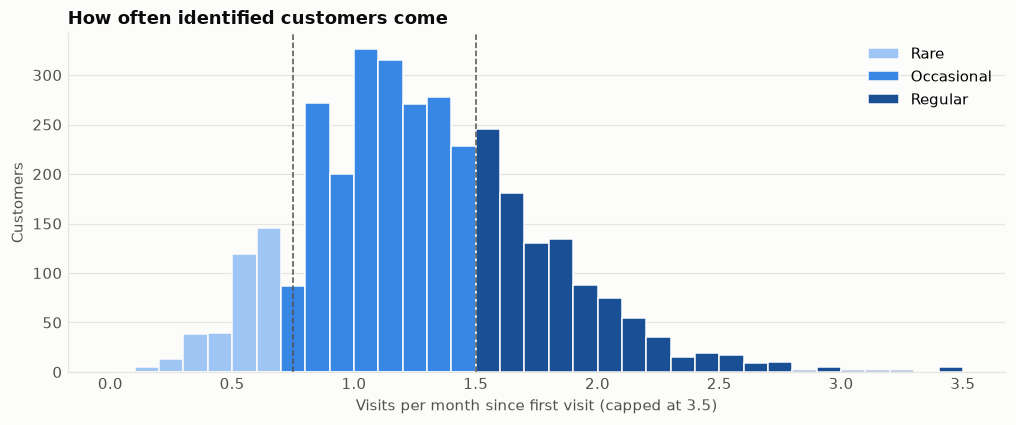

,customers,median_visits_per_month,median_orders,median_days_between_visits,median_days_since_last_visit,share_of_customers
segment,,,,,,
Regular,"1,031",1.76,9,13,9,30%
Occasional,"1,977",1.14,6,22,18,57%
Rare,444,0.61,3,49,42,13%
New,42,1.77,2,14,15,1%


In [2]:
fig, ax = plt.subplots(figsize=(11, 4))
rate = cust.loc[cust["segment"] != "New", "visits_per_month"].clip(upper=3.5)
bins = np.arange(0, 3.55, 0.1)
for seg, lo, hi in [("Rare", 0, OCCASIONAL_RATE), ("Occasional", OCCASIONAL_RATE, REGULAR_RATE), ("Regular", REGULAR_RATE, 9)]:
    ax.hist(rate[(rate >= lo) & (rate < hi)], bins=bins, color=SEG_COLORS[seg], label=seg, edgecolor=SURFACE, linewidth=1)
for x in [OCCASIONAL_RATE, REGULAR_RATE]:
    ax.axvline(x, color=INK2, lw=1, ls="--")
ax.set_xlabel("Visits per month since first visit (capped at 3.5)")
ax.set_ylabel("Customers")
ax.set_title("How often identified customers come")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.show()

seg_summary = cust.groupby("segment", observed=True).agg(
    customers=("orders", "size"), median_visits_per_month=("visits_per_month", "median"),
    median_orders=("orders", "median"), median_days_between_visits=("usual_gap_days", "median"),
    median_days_since_last_visit=("recency_days", "median"))
seg_summary["share_of_customers"] = seg_summary["customers"] / seg_summary["customers"].sum()
seg_summary.style.format({"customers": "{:,.0f}", "median_visits_per_month": "{:.2f}", "median_orders": "{:.0f}",
                          "median_days_between_visits": "{:.0f}", "median_days_since_last_visit": "{:.0f}",
                          "share_of_customers": "{:.0%}"})

**Takeaway:** about **1,030 customers (30%) are regulars**. The typical regular comes every **13 days** and was last seen 9 days ago. Most customers (57%) are occasional, coming about once a month.

## 3. How much regulars are worth

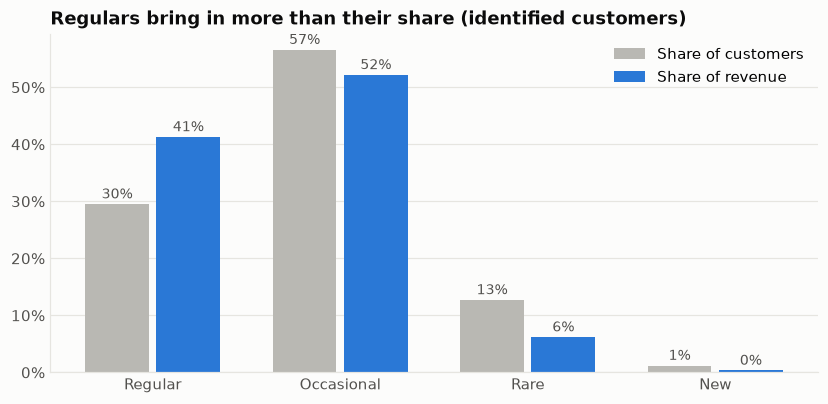

,share of identified customers,share of identified revenue,share of ALL revenue (incl. anonymous),revenue per customer
segment,,,,
Regular,29.5%,41.3%,26.2%,$78
Occasional,56.6%,52.2%,33.1%,$51
Rare,12.7%,6.2%,3.9%,$27
New,1.2%,0.3%,0.2%,$16


In [3]:
value = orders.groupby("segment").agg(orders=("revenue", "size"), revenue=("revenue", "sum"), profit=("profit", "sum"))
value = value.reindex(["Regular", "Occasional", "Rare", "New", "Anonymous"])
value["customers"] = cust["segment"].value_counts().reindex(value.index)
ident = value.drop("Anonymous")
ident_share = pd.DataFrame({
    "share of identified customers": ident["customers"] / ident["customers"].sum(),
    "share of identified revenue": ident["revenue"] / ident["revenue"].sum(),
    "share of ALL revenue (incl. anonymous)": value["revenue"].drop("Anonymous") / value["revenue"].sum(),
})
ident_share["revenue per customer"] = ident["revenue"] / ident["customers"]

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(ident_share))
w = 0.38
ax.bar(x - w / 2, ident_share["share of identified customers"], width=w - 0.04, color=MUTED, label="Share of customers")
ax.bar(x + w / 2, ident_share["share of identified revenue"], width=w - 0.04, color=ACCENT, label="Share of revenue")
for xi, (a, b) in enumerate(ident_share[["share of identified customers", "share of identified revenue"]].values):
    ax.text(xi - w / 2, a + 0.01, f"{a:.0%}", ha="center", color=INK2, fontsize=9)
    ax.text(xi + w / 2, b + 0.01, f"{b:.0%}", ha="center", color=INK2, fontsize=9)
ax.set_xticks(x, ident_share.index)
ax.yaxis.set_major_formatter(pct)
ax.set_title("Regulars bring in more than their share (identified customers)")
ax.legend(loc="upper right")
ax.grid(axis="x", visible=False)
plt.show()

ident_share.style.format({c: "{:.1%}" for c in ident_share.columns[:3]} | {"revenue per customer": "${:,.0f}"})

**Takeaway:** regulars are **30% of identified customers but bring in 41% of identified revenue**, or about 26% of *all* revenue including anonymous walk-ins. Each regular spent about **$78** over the period, compared with about $51 for an occasional customer and $27 for a rare one. Their value comes from **coming more often, not from spending more per visit** (see section 6).

## 4. Regulars by branch

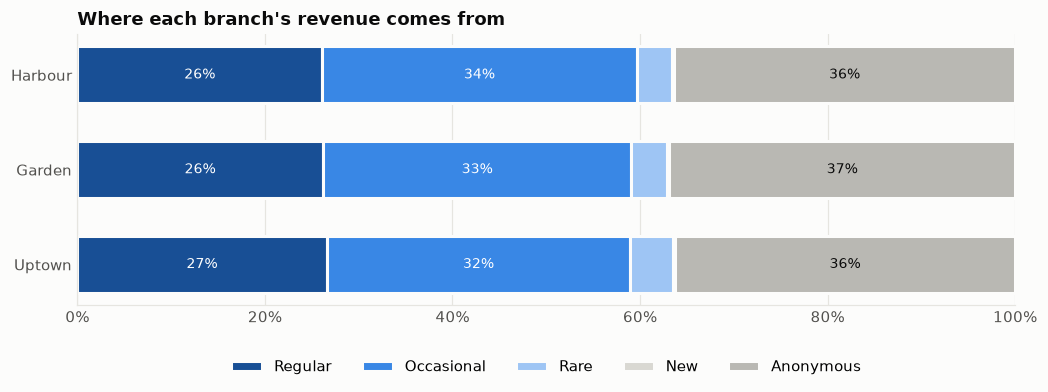

In [4]:
# Share of each branch's revenue by segment (anonymous included, so the bars add up to 100%)
mix = orders.groupby(["branch", "segment"])["revenue"].sum().unstack()[["Regular", "Occasional", "Rare", "New", "Anonymous"]]
mix = mix.div(mix.sum(axis=1), axis=0).loc[BRANCHES]

fig, ax = plt.subplots(figsize=(11, 3.2))
left = np.zeros(len(mix))
for seg in mix.columns:
    vals = mix[seg].values
    ax.barh(mix.index, vals, left=left, color=SEG_COLORS[seg], label=seg, edgecolor=SURFACE, linewidth=2, height=0.6)
    for yi, (l, v) in enumerate(zip(left, vals)):
        if v >= 0.06:
            ax.text(l + v / 2, yi, f"{v:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if seg in ("Regular", "Occasional") else INK)
    left += vals
ax.xaxis.set_major_formatter(pct)
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.set_title("Where each branch's revenue comes from")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncols=5)
ax.grid(axis="y", visible=False)
plt.show()

In [5]:
by_home = cust[cust["segment"] != "New"].groupby("home_branch")["segment"].value_counts(normalize=True).unstack()
by_home = by_home[["Regular", "Occasional", "Rare"]].loc[BRANCHES]
by_home["customers (home branch)"] = cust[cust["segment"] != "New"]["home_branch"].value_counts()
by_home["avg share of visits at home branch"] = cust.groupby("home_branch")["home_share"].mean()
by_home["regulars using 2+ branches"] = cust[cust["segment"] == "Regular"].groupby("home_branch")["branches_used"].apply(
    lambda s: (s >= 2).mean())
by_home.style.format({"Regular": "{:.0%}", "Occasional": "{:.0%}", "Rare": "{:.0%}", "customers (home branch)": "{:,.0f}",
                      "avg share of visits at home branch": "{:.0%}", "regulars using 2+ branches": "{:.0%}"})

segment,Regular,Occasional,Rare,customers (home branch),avg share of visits at home branch,regulars using 2+ branches
home_branch,,,,,,
Harbour,32%,57%,11%,"1,936",63%,99%
Garden,27%,57%,15%,"1,293",53%,100%
Uptown,26%,56%,19%,223,60%,98%


**Takeaway**
- Regulars bring in about the **same share of revenue at every branch** (26-27%), and anonymous walk-ins about 36%.
- **"Home branch"** is the branch a customer visits most. Even so, the average customer makes only 53-63% of their visits there, and **98-100% of regulars use two or three branches**. Regulars are loyal to **Stories as a brand**, not to one location, so a loyalty program should work across all branches.
- Harbour has the highest share of regulars among its home customers (32%, vs 27% at Garden and 26% at Uptown). Only about 220 customers have Uptown as their home branch, because it's the smallest branch.

## 5. Visit rhythm: how often, which days, what time

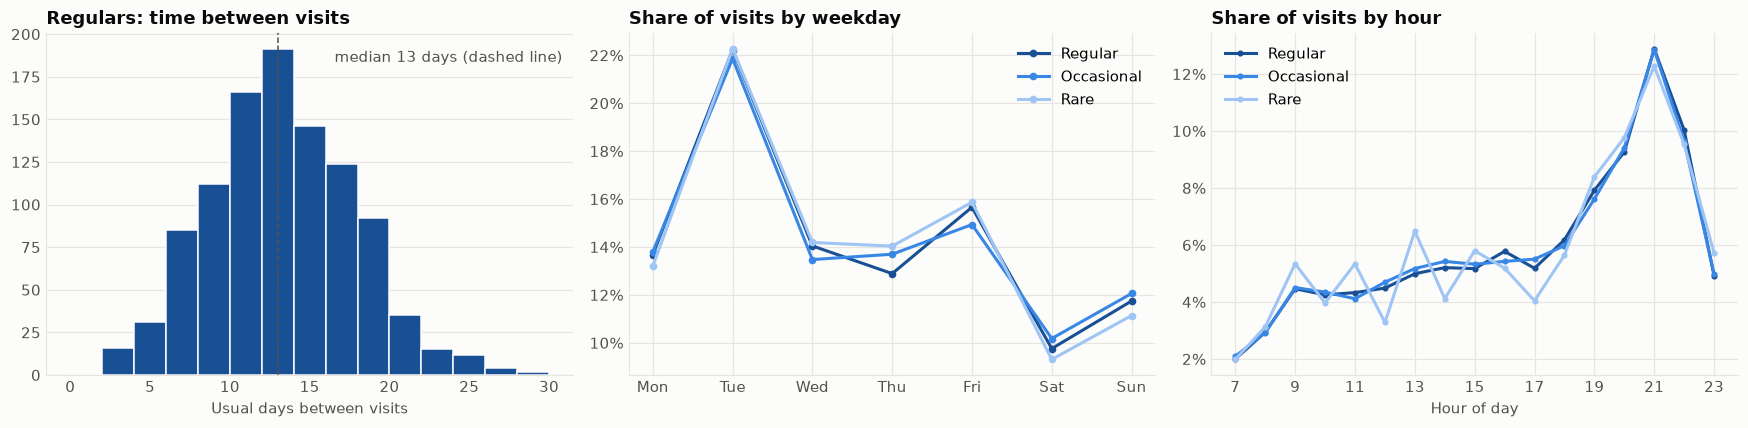

In [6]:
reg = cust[cust["segment"] == "Regular"]
seg_orders = known[known["segment"].isin(["Regular", "Occasional", "Rare"])]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ax = axes[0]
ax.hist(reg["usual_gap_days"].dropna(), bins=np.arange(0, 32, 2), color=SEG_COLORS["Regular"], edgecolor=SURFACE)
ax.axvline(reg["usual_gap_days"].median(), color=INK2, ls="--", lw=1)
ax.text(0.98, 0.95, f"median {reg['usual_gap_days'].median():.0f} days (dashed line)",
        transform=ax.transAxes, color=INK2, va="top", ha="right")
ax.set_xlabel("Usual days between visits")
ax.set_title("Regulars: time between visits")
ax.grid(axis="x", visible=False)

ax = axes[1]
dow_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
for seg in ["Regular", "Occasional", "Rare"]:
    s = seg_orders[seg_orders["segment"] == seg]["date"].dt.dayofweek.value_counts(normalize=True).sort_index()
    ax.plot(dow_names, s.values, color=SEG_COLORS[seg], marker="o", ms=4, label=seg)
ax.yaxis.set_major_formatter(pct)
ax.set_title("Share of visits by weekday")
ax.legend(loc="upper right")

ax = axes[2]
for seg in ["Regular", "Occasional", "Rare"]:
    s = seg_orders[seg_orders["segment"] == seg]["hour"].value_counts(normalize=True).sort_index()
    ax.plot(s.index, s.values, color=SEG_COLORS[seg], marker="o", ms=3, label=seg)
ax.yaxis.set_major_formatter(pct)
ax.set_xticks(range(7, 24, 2))
ax.set_xlabel("Hour of day")
ax.set_title("Share of visits by hour")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [7]:
# Do customers have a habit? Share of each customer's visits on their most common weekday / at their most common branch
habit = known.assign(dow=known["date"].dt.dayofweek).groupby("customer").agg(
    same_weekday=("dow", lambda s: s.value_counts(normalize=True).iloc[0]),
    same_daypart=("hour", lambda s: pd.cut(s, [0, 10, 17, 24]).value_counts(normalize=True).iloc[0]),
)
habit["segment"] = cust["segment"]
habit[habit["segment"] != "New"].groupby("segment", observed=True)[["same_weekday", "same_daypart"]].mean().style.format("{:.0%}")

,same_weekday,same_daypart
segment,,
Regular,35%,58%
Occasional,41%,61%
Rare,53%,70%


**Takeaway**
- The typical regular comes back every **10 to 16 days**.
- Regulars follow the **same weekly and daily pattern as everyone else**: Tuesday is the busiest day and 21:00 the busiest hour. They aren't a separate "morning commuter" crowd.
- **Regulars don't have a fixed routine.** Only about a third of a regular's visits fall on their most common weekday, close to what you'd get if days were random. That makes "your usual Tuesday" style messages less useful than general reminders.

## 6. What regulars buy

In [8]:
items = df.dropna(subset=["Customer ID"]).assign(segment=lambda d: d["Customer ID"].map(cust["segment"]))
items = items[items["segment"].isin(["Regular", "Occasional", "Rare"])]

basket = known[known["segment"].isin(["Regular", "Occasional", "Rare"])].groupby("segment", observed=True).agg(
    aov=("revenue", "mean"), items_per_order=("items", "mean"),
    takeaway_share=("order_type", lambda s: (s == "Takeaway").mean()),
    margin=("profit", "sum"))
basket["margin"] = basket["margin"] / known.groupby("segment", observed=True)["revenue"].sum().reindex(basket.index)

# Product loyalty: share of a customer's orders that include their single favorite product
fav = items.groupby(["Customer ID", "Product"])["Transaction ID"].nunique().reset_index(name="orders_with")
fav = fav.sort_values("orders_with").groupby("Customer ID").tail(1).set_index("Customer ID")
fav["share"] = fav["orders_with"] / cust.loc[fav.index, "orders"]
basket["orders including their favorite product"] = fav.groupby(cust.loc[fav.index, "segment"], observed=True)["share"].mean()
basket.style.format({"aov": "${:.2f}", "items_per_order": "{:.2f}", "takeaway_share": "{:.0%}", "margin": "{:.1%}",
                     "orders including their favorite product": "{:.0%}"})

,aov,items_per_order,takeaway_share,margin,orders including their favorite product
segment,,,,,
Regular,$8.97,1.60,41%,58.7%,24%
Occasional,$9.00,1.58,39%,58.7%,28%
Rare,$9.15,1.60,43%,58.7%,45%


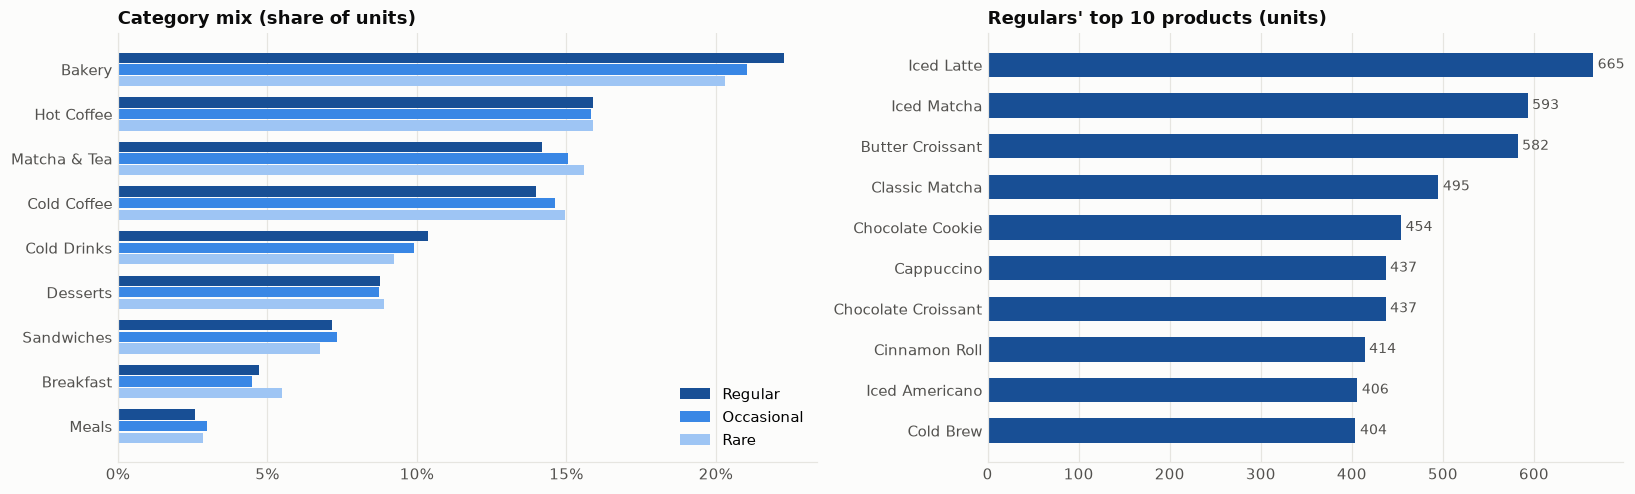

In [9]:
mix = pd.crosstab(items["Category"], items["segment"], values=items["Quantity"], aggfunc="sum", normalize="columns")
mix = mix[["Regular", "Occasional", "Rare"]].sort_values("Regular", ascending=False)
top_products = (items[items["segment"] == "Regular"].groupby("Product")["Quantity"].sum()
                .sort_values(ascending=False).head(10))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
y = np.arange(len(mix))
h = 0.26
for i, seg in enumerate(["Regular", "Occasional", "Rare"]):
    ax.barh(y + (i - 1) * h, mix[seg], height=h - 0.03, color=SEG_COLORS[seg], label=seg)
ax.set_yticks(y, mix.index)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct)
ax.set_title("Category mix (share of units)")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh(top_products.index[::-1], top_products.values[::-1], color=SEG_COLORS["Regular"], height=0.6)
for i, v in enumerate(top_products.values[::-1]):
    ax.text(v + 5, i, f"{v:,}", va="center", color=INK2, fontsize=9)
ax.set_title("Regulars' top 10 products (units)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**Takeaway**
- **Regulars spend the same per visit** as other customers (about $9.00, 1.6 items) and buy the same mix of products. Their extra value comes entirely from **visiting more often**.
- **Regulars don't stick to one product.** Their favorite item appears in only about a quarter of their orders, so they explore the menu. That makes them a good audience for new items and bundles (for example matcha + pastry, see `01_eda`).
- Their top products are the café's bestsellers overall: Iced Latte, Iced Matcha, Butter Croissant and Classic Matcha.

## 7. Discounts: are regulars rewarded?

In [10]:
disc = known[known["segment"].isin(["Regular", "Occasional", "Rare"])].groupby("segment", observed=True)["discount"].agg(
    discounted_orders=lambda s: (s > 0).mean(), ten_pct=lambda s: (s == 0.10).mean(), fifteen_pct=lambda s: (s == 0.15).mean())
disc.style.format("{:.1%}")

,discounted_orders,ten_pct,fifteen_pct
segment,,,
Regular,9.3%,8.1%,1.2%
Occasional,9.8%,8.2%,1.6%
Rare,9.7%,8.8%,0.9%


**Takeaway:** regulars get a discount on about **10% of their orders, the same rate as occasional and rare customers**. Whatever the 10% discount is, it isn't a loyalty reward: frequent customers get nothing extra for coming back. That's a clear gap a loyalty program could fill.

## 8. Retention: do customers keep coming back?

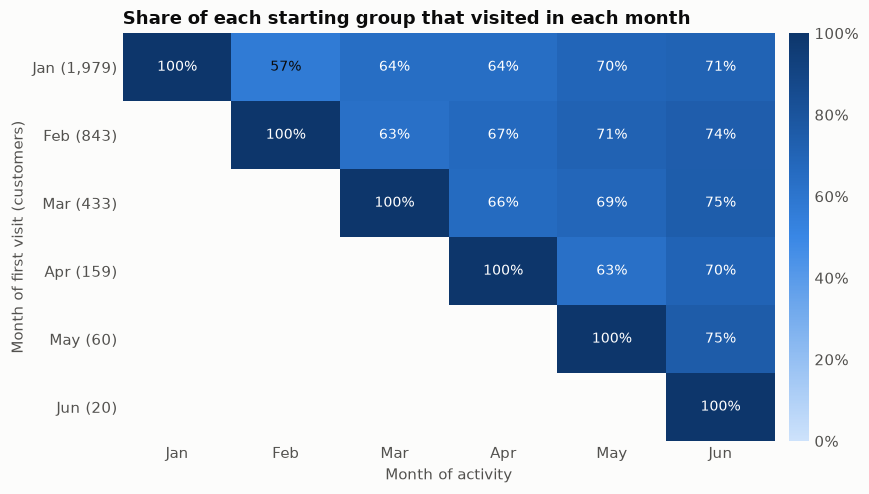

In [11]:
k = known.assign(cohort=known["customer"].map(cust["first"]).dt.to_period("M"), month=known["date"].dt.to_period("M"))
active = k.groupby(["cohort", "month"])["customer"].nunique().unstack()
cohort_size = cust.groupby(cust["first"].dt.to_period("M")).size()
retention = active.div(cohort_size, axis=0)

fig, ax = plt.subplots(figsize=(8, 4.6))
im = ax.imshow(retention.values, cmap=LinearSegmentedColormap.from_list("seq", SEQ), vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(retention.shape[1]), [p.strftime("%b") for p in retention.columns])
ax.set_yticks(range(retention.shape[0]), [f"{p.strftime('%b')} ({cohort_size[p]:,})" for p in retention.index])
ax.set_xlabel("Month of activity")
ax.set_ylabel("Month of first visit (customers)")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(retention.shape[0]):
    for j in range(retention.shape[1]):
        v = retention.iat[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, format=pct)
cb.outline.set_visible(False)
ax.set_title("Share of each starting group that visited in each month")
plt.tight_layout()
plt.show()

**Takeaway**
- Of the customers who first came in January, **57% came back in February**, and by June **71%** were still visiting each month. The same pattern holds for every starting month: roughly 60-65% come back the next month, and that share **rises** over time instead of falling.
- In other words, once a customer has been identified, they tend to stay. The weak spot is earlier in the funnel: new sign-ups dropped from about 2,000 in January to 20 in June (see `01_eda`). *Rising retention is unusual for a real café, so this may be a feature of the synthetic data.*

## 9. Regulars at risk

A regular is **overdue** if they haven't visited for more than twice their usual gap between visits, and for at least three weeks. For example, someone who normally comes every 12 days and hasn't been seen for 25 days is overdue.

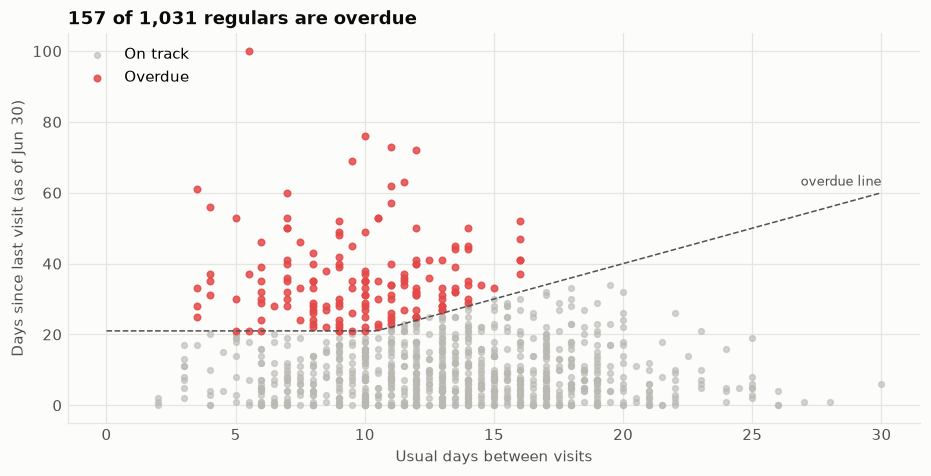

,regulars,overdue,overdue_share,spend_of_overdue_regulars
home_branch,,,,
Harbour,620,90,15%,"$7,001"
Garden,354,57,16%,"$4,513"
Uptown,57,10,18%,$772
All,"1,031",157,15%,"$12,287"


In [12]:
reg = cust[cust["segment"] == "Regular"].copy()
reg["overdue"] = (reg["recency_days"] > 2 * reg["usual_gap_days"]) & (reg["recency_days"] >= 21)

fig, ax = plt.subplots(figsize=(10, 4.6))
ok, late = reg[~reg["overdue"]], reg[reg["overdue"]]
ax.scatter(ok["usual_gap_days"], ok["recency_days"], s=14, color=MUTED, alpha=0.6, label="On track")
ax.scatter(late["usual_gap_days"], late["recency_days"], s=18, color=NEG, alpha=0.85, label="Overdue")
g = np.linspace(0, reg["usual_gap_days"].max(), 50)
ax.plot(g, np.maximum(2 * g, 21), color=INK2, lw=1, ls="--")
ax.text(g[-1], max(2 * g[-1], 21) + 2, "overdue line", ha="right", color=INK2, fontsize=8.5)
ax.set_xlabel("Usual days between visits")
ax.set_ylabel("Days since last visit (as of Jun 30)")
ax.set_title(f"{reg['overdue'].sum()} of {len(reg):,} regulars are overdue")
ax.legend(loc="upper left")
plt.show()

risk = reg.groupby("home_branch").agg(regulars=("overdue", "size"), overdue=("overdue", "sum"))
risk["overdue_share"] = risk["overdue"] / risk["regulars"]
risk["spend_of_overdue_regulars"] = reg[reg["overdue"]].groupby("home_branch")["spend"].sum()
risk.loc["All"] = [len(reg), reg["overdue"].sum(), reg["overdue"].mean(), reg.loc[reg["overdue"], "spend"].sum()]
risk.loc[[*BRANCHES, "All"]].style.format({"regulars": "{:,.0f}", "overdue": "{:,.0f}", "overdue_share": "{:.0%}",
                                           "spend_of_overdue_regulars": "${:,.0f}"})

**Takeaway:** **157 regulars (15%) are overdue**, at a similar rate at every branch (15-18%). Together they spent about **$12k** in the first half of the year. They're the cheapest customers to win back, because they already know and like the café. A "we miss you" offer, triggered automatically when a regular passes their overdue line, is a simple, measurable campaign.

## 10. Conclusion and business ideas

| Finding | Evidence | Business idea |
|---|---|---|
| **Regulars are worth more** | 30% of identified customers, 41% of identified revenue; about $78 each vs $51 for occasional | Protect them first: they're the café's most valuable group |
| **Their value is frequency, not basket size** | Same order value ($9.00), items and product mix as everyone else | Reward visit frequency (for example a stamp card: every 8th drink free) rather than spend |
| **They aren't rewarded today** | Discount rate identical (about 10%) across segments | Turn the existing discount budget into a loyalty program |
| **They're brand-loyal, not branch-loyal** | 98-100% of regulars use 2-3 branches; only 53-63% of visits at their home branch | Make the program work at all three branches |
| **They explore the menu** | Favorite product in only about a quarter of their orders | Use regulars to launch new items and bundles |
| **Some are slipping away** | 157 regulars (15%) overdue, worth about $12k so far | Automatic "we miss you" offer when a regular passes their overdue line |
| **Occasional customers are the next regulars** | 57% of customers, about once a month | Nudge them toward 2 visits a month with a time-limited "come back within 14 days" offer |
| **36% of orders are anonymous** | No customer ID | Push sign-ups at the till, since sign-ups have nearly stopped (see `01_eda`) |

*The data is synthetic, so behavior may be more uniform than in a real café, for example identical spend per visit across segments and rising retention.*